# ML в индустрии

**Часть 1 (Семинар, ~40 мин):** ML vs бизнес-метрики, метрики рекомендаций, мониторинг дрейфа.

**Зависимости:** `pip install pandas numpy scikit-learn lightgbm shap onnx onnxruntime onnxscript fastapi uvicorn evidently requests`

In [1]:
%pip install pandas numpy scikit-learn lightgbm shap onnx onnxruntime onnxscript fastapi uvicorn evidently requests --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install evidently --quiet

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, precision_recall_curve, auc, confusion_matrix, roc_auc_score, brier_score_loss, f1_score
from sklearn.calibration import calibration_curve

import lightgbm as lgb

import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

---
## 🎯 Часть 1. СЕМИНАР: Бизнес-метрики и мониторинг

### 1.1. Разрыв между ML- и бизнес-метрикой (Cost-Sensitive Threshold)
Смоделируем задачу детекции фрода: 1% мошенников, стоимость ложного пропуска (FN) = 50 000 ₽, ложной тревоги (FP) = 500 ₽. Сравним порог по F1 и порог по бизнес-стоимости.

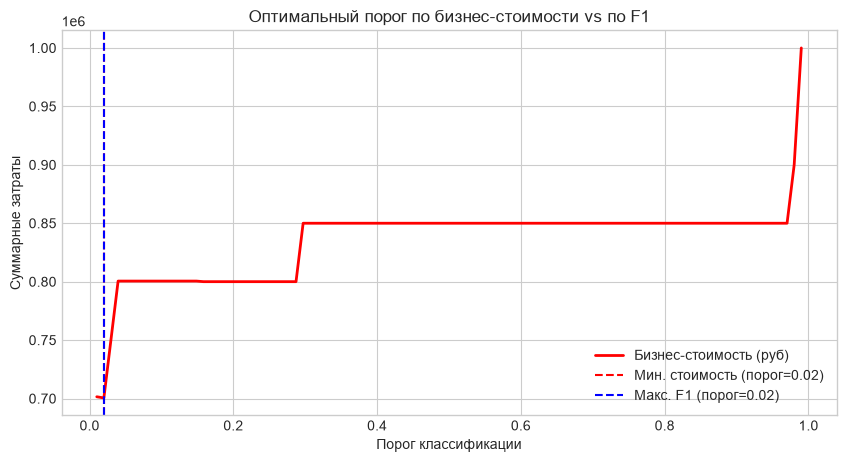

Порог по F1:        0.020 (F1=0.483, стоимость=700,500 ₽)
Порог по стоимости: 0.020 (F1=0.483, стоимость=700,500 ₽)


In [4]:
# Генерируем синтетику: 5 000 транзакций, 1% фрода
X_syn, y_syn = make_classification(
    n_samples=5000, n_features=15, n_informative=8, n_redundant=3,
    weights=[0.99, 0.01], flip_y=0.01, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X_syn, y_syn, test_size=0.3, random_state=42, stratify=y_syn)

# Обучаем LightGBM (подходит для табличного фрода)
lgb_fraud = lgb.LGBMClassifier(n_estimators=100, random_state=42, verbose=-1)
lgb_fraud.fit(X_train, y_train)
y_proba = lgb_fraud.predict_proba(X_test)[:, 1]

# Рассчитываем бизнес-стоимость для каждого порога
thresholds = np.linspace(0.01, 0.99, 100)
total_costs = []
f1_scores = []

for t in thresholds:
    y_pred = (y_proba >= t).astype(int)
    fn = ((y_test == 1) & (y_pred == 0)).sum()
    fp = ((y_test == 0) & (y_pred == 1)).sum()
    total_costs.append(fn * 50000 + fp * 500)
    f1_scores.append(f1_score(y_test, y_pred))

best_cost_idx = np.argmin(total_costs)
best_f1_idx = np.argmax(f1_scores)

plt.figure(figsize=(10, 5))
plt.plot(thresholds, total_costs, label='Бизнес-стоимость (руб)', color='red', linewidth=2)
plt.axvline(thresholds[best_cost_idx], color='red', linestyle='--', label=f'Мин. стоимость (порог={thresholds[best_cost_idx]:.2f})')
plt.axvline(thresholds[best_f1_idx], color='blue', linestyle='--', label=f'Макс. F1 (порог={thresholds[best_f1_idx]:.2f})')
plt.xlabel('Порог классификации')
plt.ylabel('Суммарные затраты')
plt.title('Оптимальный порог по бизнес-стоимости vs по F1')
plt.legend()
plt.show()

print(f"Порог по F1:        {thresholds[best_f1_idx]:.3f} (F1={f1_scores[best_f1_idx]:.3f}, стоимость={total_costs[best_f1_idx]:,.0f} ₽)")
print(f"Порог по стоимости: {thresholds[best_cost_idx]:.3f} (F1={f1_scores[best_cost_idx]:.3f}, стоимость={total_costs[best_cost_idx]:,.0f} ₽)")

**Вывод:** порог, оптимальный по F1, может быть экономически невыгодным. Бизнес-порог смещается в сторону более высокого Recall, чтобы ловить больше фрода, даже ценой ложных тревог.

### 1.2. Метрики рекомендательных систем: NDCG@K
Рекомендательные системы оценивают не только точность, но и **качество ранжирования**. Реализуем NDCG@K с нуля.

In [5]:
def ndcg_at_k(relevances, k):
    """relevances: бинарный список (1 - релевантно, 0 - нет) в порядке выдачи."""
    relevances = np.asarray(relevances[:k])
    discounts = 1.0 / np.log2(np.arange(2, len(relevances) + 2))
    dcg = np.sum(relevances * discounts)
    ideal_relevances = np.sort(relevances)[::-1]
    idcg = np.sum(ideal_relevances * discounts)
    return dcg / idcg if idcg > 0 else 0.0

# Пример: пользователю показали 5 товаров, релевантные — на позициях 1 и 4
relevance_list = [1, 0, 0, 1, 0]
for k in [3, 5]:
    print(f"NDCG@{k} = {ndcg_at_k(relevance_list, k):.3f}")

NDCG@3 = 1.000
NDCG@5 = 0.877


### 1.3. Мониторинг дрейфа (PSI и Evidently AI)
Смоделируем ситуацию: модель обучена на одних данных, а в production пришли данные с изменившимся распределением. Рассчитаем **PSI (Population Stability Index)** и построим отчёт Evidently.

In [6]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification

# Генерируем train и "сдвинутый" production
X_train_drift, _ = make_classification(n_samples=1000, n_features=5, n_informative=3, random_state=42)
X_prod_drift = X_train_drift.copy()
X_prod_drift[:, 0] += 1.5
X_prod_drift[:, 1] *= 0.5

# PSI для первого признака
def calculate_psi(expected, actual, buckets=10):
    def scale_range(input_array, min_val, max_val):
        input_array += -(np.min(input_array))
        input_array /= np.max(input_array) / (max_val - min_val)
        input_array += min_val
        return input_array

    breakpoints = np.arange(0, buckets + 1) / (buckets) * 100
    breakpoints = scale_range(breakpoints, np.min(expected), np.max(expected))
    expected_percents = np.histogram(expected, breakpoints)[0] / len(expected)
    actual_percents = np.histogram(actual, breakpoints)[0] / len(actual)

    def sub_psi(e_perc, a_perc):
        if e_perc == 0: e_perc = 0.0001
        if a_perc == 0: a_perc = 0.0001
        return (e_perc - a_perc) * np.log(e_perc / a_perc)

    return sum(sub_psi(expected_percents[i], actual_percents[i]) for i in range(len(expected_percents)))

psi_val = calculate_psi(X_train_drift[:, 0], X_prod_drift[:, 0])
print(f"PSI для признака 0: {psi_val:.3f}")

# --- Отчёт Evidently (новый API 1.0+) ---
try:
    from evidently import Dataset, DataDefinition, Report
    from evidently.presets import DataDriftPreset

    # Приводим numpy-массивы к DataFrame с понятными именами колонок
    df_ref = pd.DataFrame(X_train_drift, columns=[f'f{i}' for i in range(5)])
    df_prod = pd.DataFrame(X_prod_drift, columns=[f'f{i}' for i in range(5)])

    # Определяем схему (все признаки числовые)
    schema = DataDefinition(numerical_columns=df_ref.columns.tolist())

    # Оборачиваем в Dataset
    eval_ref = Dataset.from_pandas(df_ref, data_definition=schema)
    eval_prod = Dataset.from_pandas(df_prod, data_definition=schema)

    # Запускаем отчёт
    report = Report([DataDriftPreset()])
    my_eval = report.run(eval_prod, eval_ref)  # первый аргумент — текущие данные, второй — эталон

    # Сохраняем HTML
    my_eval.save_html("drift_report1.html")
    print("\nОтчёт Evidently сохранён в drift_report.html (новый API 1.0+).")

except ImportError:
    print("\n[Ошибка импорта] Похоже, установлена версия < 1.0 или > 1.0, но с другим API.")
    print("Выполните: pip install \"evidently==0.6.7\" и перезапустите среду.")
except Exception as e:
    print(f"\n[Ошибка выполнения] {e}")

PSI для признака 0: 2.254

Отчёт Evidently сохранён в drift_report.html (новый API 1.0+).


In [ ]:
# Способ 1. Генерируем train и еще более "сдвинутый" production
X_train_drift, _ = make_classification(
    n_samples=1000, n_features=5, n_informative=3, random_state=42
)
X_prod_drift = X_train_drift.copy()

# Сильный дрифт сразу в 4 из 5 признаков
X_prod_drift[:, 0] += 3.0    # сдвиг среднего вправо
X_prod_drift[:, 1] *= 0.1    # сжатие дисперсии (коллапс)
X_prod_drift[:, 2] += 2.5    # сдвиг среднего
X_prod_drift[:, 3] += np.random.normal(0, 2, size=len(X_prod_drift))  # добавление шума
# f4 оставляем нетронутым — как «стабильный» признак

df_ref = pd.DataFrame(X_train_drift, columns=[f'f{i}' for i in range(5)])
df_prod = pd.DataFrame(X_prod_drift, columns=[f'f{i}' for i in range(5)])

schema = DataDefinition(numerical_columns=df_ref.columns.tolist())
eval_ref = Dataset.from_pandas(df_ref, data_definition=schema)
eval_prod = Dataset.from_pandas(df_prod, data_definition=schema)
# 4. Запускаем отчёт
report = Report([DataDriftPreset()])
result = report.run(eval_prod, eval_ref)
my_eval.save_html("drift_report2.html")

In [ ]:
# Способ 2. Можно понизить порог 
from evidently.presets import DataDriftPreset

# Порог 0.2: достаточно, чтобы дрифтнул хотя бы 1 из 5 признаков
report = Report([
    DataDriftPreset(drift_share=0.2)  # 20% признаков сдвинулось -> дрифт
])
result = report.run(eval_prod, eval_ref)
my_eval.save_html("drift_report3.html")

In [ ]:
# Или по каждому признаку в отдельности
report = Report([
    DataDriftPreset(
        stattest="ks",              # используем KS-тест
        stattest_threshold=0.05,    # порог p-value
        drift_share=0.5,            # порог доли признаков на уровне датасета
    )
])
result = report.run(eval_prod, eval_ref)
my_eval.save_html("drift_report4.html")